# Atividade 3 — Regressão Logística (Softmax) no Dataset Breast Cancer Wisconsin

* **Aluna:** Taísa Tavares Cruz

## Objetivos

- Realizar uma análise exploratória inicial do dataset *Breast Cancer Wisconsin* (distribuição das classes e significado das variáveis).
- Dividir os dados de forma estratificada (80% treino / 20% teste) e aplicar `StandardScaler` ajustado exclusivamente nos dados de treino.
- Treinar um classificador linear `nn.Linear(30, 2)` com `nn.CrossEntropyLoss` e `optim.SGD`, acompanhando as curvas de custo de treino e teste.
- Comparar a acurácia no conjunto de teste com o modelo *baseline* (classe majoritária).
- Avaliar a matriz de confusão, calcular o *recall* da classe **maligno** e discutir o impacto clínico entre falsos negativos e falsos positivos.

## 1. Importação das Bibliotecas e Análise Exploratória dos Dados

O conjunto de dados *Breast Cancer Wisconsin (Diagnostic)* contém **569 amostras** de exames de biópsia por aspiração com agulha fina (PAAF) de massas mamárias, descritas por **30 variáveis numéricas** computadas a partir de imagens digitalizadas dos núcleos celulares:

- **Classes (`y`):**
  - `0` — **Maligno** (*malignant*)
  - `1` — **Benigno** (*benign*)
- **O que as variáveis medem:** Para cada imagem, são calculadas 10 características morfológicas básicas dos núcleos celulares — como **raio** (`radius`, distância média do centro ao perímetro), **textura** (`texture`, desvio padrão dos valores da escala de cinza), **perímetro** (`perimeter`), **área** (`area`), **suavidade** (`smoothness`), **compacidade** (`compactness`), **concavidade** (`concavity`), **pontos côncavos** (`concave points`), **simetria** (`symmetry`) e **dimensão fractal** (`fractal dimension`). Para cada uma dessas 10 métricas, o dataset registra a **média** (`mean`), o **erro padrão** (`error`) e o **pior/maior valor** (`worst`), totalizando $10 \times 3 = 30$ atributos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, recall_score

import torch
import torch.nn as nn
import torch.nn.functional as F

# Semente fixa para reprodutibilidade
torch.manual_seed(42)
np.random.seed(42)

# Carregamento dos dados
dados = load_breast_cancer(as_frame=True)
X, y = dados.data, dados.target  # 569 amostras, 30 variáveis; 0 = maligno, 1 = benigno

print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print("\nNomes das classes:", dict(enumerate(dados.target_names)))

# Contagem e proporção das classes
contagem = y.value_counts().sort_index()
proporcao = y.value_counts(normalize=True).sort_index() * 100

resumo_classes = pd.DataFrame({
    'Classe': ['0 - Maligno', '1 - Benigno'],
    'Amostras': contagem.values,
    'Percentual (%)': proporcao.values.round(2)
})
display(resumo_classes)

# Estatísticas descritivas de algumas variáveis principais (médias)
colunas_exemplo = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean concavity']
print("\nResumo estatístico de 5 variáveis selecionadas:")
display(X[colunas_exemplo].describe().round(2))

Shape de X: (569, 30)
Shape de y: (569,)

Nomes das classes: {0: np.str_('malignant'), 1: np.str_('benign')}


,Classe,Amostras,Percentual (%)
0,0 - Maligno,212,37.26
1,1 - Benigno,357,62.74



Resumo estatístico de 5 variáveis selecionadas:


,mean radius,mean texture,mean perimeter,mean area,mean concavity
count,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.09
std,3.52,4.30,24.30,351.91,0.08
min,6.98,9.71,43.79,143.50,0.00
25%,11.70,16.17,75.17,420.30,0.03
50%,13.37,18.84,86.24,551.10,0.06
75%,15.78,21.80,104.10,782.70,0.13
max,28.11,39.28,188.50,2501.00,0.43


## 2. Divisão Estratificada e Padronização (`StandardScaler`)

Para evitar vazamento de dados (*data leakage*), seguimos duas boas práticas fundamentais:
1. **Divisão estratificada (`stratify=y`):** Garante que a proporção original (~37,3% malignos e ~62,7% benignos) seja preservada tanto no conjunto de treino (80% = 455 amostras) quanto no de teste (20% = 114 amostras).
2. **Padronização ajustada apenas no treino:** O `StandardScaler` calcula a média $\mu$ e o desvio padrão $\sigma$ de cada uma das 30 variáveis **somente** em `X_train` (`fit_transform`), aplicando depois essa mesma transformação em `X_test` (`transform`).

In [2]:
# Divisão estratificada 80/20 com random_state fixo
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Padronização ajustada exclusivamente nos dados de treino
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Conversão para tensores do PyTorch
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.long)

print("Treino:", X_train_t.shape, y_train_t.shape)
print("Teste: ", X_test_t.shape, y_test_t.shape)

Treino: torch.Size([455, 30]) torch.Size([455])
Teste:  torch.Size([114, 30]) torch.Size([114])


## 3. Modelo e Treinamento com `optim.SGD`

Definimos uma camada linear `nn.Linear(30, 2)` que recebe os 30 atributos padronizados e produz 2 *logits* ($z_0$ para maligno e $z_1$ para benigno). O custo é calculado com `nn.CrossEntropyLoss()`, que aplica internamente a *log-softmax*, e os parâmetros são otimizados via descida do gradiente (`torch.optim.SGD`). A cada época registramos o custo (*loss*) tanto no treino quanto no teste.

Custo final (Treino): 0.0568
Custo final (Teste):  0.0874


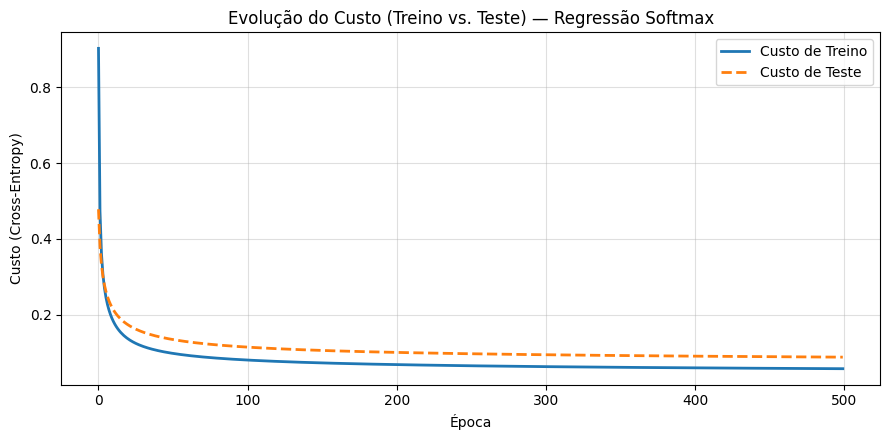

In [3]:
# Definição do modelo, função de custo e otimizador
torch.manual_seed(42)
model = nn.Linear(30, 2)

criterion = nn.CrossEntropyLoss()
lr = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

n_epochs = 500
train_losses = []
test_losses = []

for epoch in range(n_epochs):
    # --- Modo Treino ---
    model.train()
    logits_train = model(X_train_t)
    loss_train = criterion(logits_train, y_train_t)

    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()

    # --- Avaliação no Teste (sem cálculo de gradiente) ---
    model.eval()
    with torch.no_grad():
        logits_test = model(X_test_t)
        loss_test = criterion(logits_test, y_test_t)

    train_losses.append(loss_train.item())
    test_losses.append(loss_test.item())

print(f"Custo final (Treino): {train_losses[-1]:.4f}")
print(f"Custo final (Teste):  {test_losses[-1]:.4f}")

# Gráfico das curvas de custo de treino e de teste
plt.figure(figsize=(9, 4.5))
plt.plot(train_losses, label='Custo de Treino', linewidth=2)
plt.plot(test_losses, label='Custo de Teste', linewidth=2, linestyle='--')
plt.xlabel('Época')
plt.ylabel('Custo (Cross-Entropy)')
plt.title('Evolução do Custo (Treino vs. Teste) — Regressão Softmax')
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## 4. Avaliação: Acurácia vs. Baseline, Matriz de Confusão e Recall

Para verificar se o modelo realmente aprendeu padrões úteis, comparamos sua acurácia no conjunto de teste com um **classificador baseline** ingênuo (*dummy classifier*) que sempre prevê a classe mais frequente (`1` — Benigno). Em seguida, inspecionamos a matriz de confusão e o *recall* (sensibilidade) da classe **Maligno (`0`)**.

In [4]:
def predict(model, inputs):
    model.eval()
    with torch.no_grad():
        logits = model(inputs)
        probs = F.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
    return preds.numpy(), probs.numpy()

y_pred_test, y_prob_test = predict(model, X_test_t)
y_true_test = y_test_t.numpy()

# 1. Acurácia do modelo vs. Baseline (sempre prevê classe mais frequente: 1 = Benigno)
classe_majoritaria = y_train.value_counts().idxmax()
y_pred_baseline = np.full_like(y_true_test, fill_value=classe_majoritaria)

acc_modelo = (y_pred_test == y_true_test).mean()
acc_baseline = (y_pred_baseline == y_true_test).mean()

print(f"Acurácia Baseline (sempre classe '{dados.target_names[classe_majoritaria]}'): {acc_baseline:.4f} ({acc_baseline*100:.2f}%)")
print(f"Acurácia Modelo Regressão Softmax (Teste):          {acc_modelo:.4f} ({acc_modelo*100:.2f}%)")
print(f"Ganho sobre o baseline:                            +{(acc_modelo - acc_baseline)*100:.2f} pontos percentuais\n")

# 2. Matriz de Confusão
cm = confusion_matrix(y_true_test, y_pred_test, labels=[0, 1])
cm_df = pd.DataFrame(
    cm,
    index=['Real: 0 (Maligno)', 'Real: 1 (Benigno)'],
    columns=['Previsto: 0 (Maligno)', 'Previsto: 1 (Benigno)']
)
print("Matriz de Confusão (Conjunto de Teste):")
display(cm_df)

# 3. Recall da classe Maligno (classe 0)
recall_maligno = recall_score(y_true_test, y_pred_test, pos_label=0)
encontrados_em_100 = recall_maligno * 100

print(f"\nRecall da classe 'Maligno' (0): {recall_maligno:.4f} ({encontrados_em_100:.2f}%)")
print(f"Interpretação: de cada 100 tumores malignos, o modelo encontra aproximadamente {encontrados_em_100:.0f}.")

print("\nRelatório completo de classificação:")
print(classification_report(y_true_test, y_pred_test, target_names=['0 - Maligno', '1 - Benigno']))

Acurácia Baseline (sempre classe 'benign'): 0.6316 (63.16%)
Acurácia Modelo Regressão Softmax (Teste):          0.9649 (96.49%)
Ganho sobre o baseline:                            +33.33 pontos percentuais

Matriz de Confusão (Conjunto de Teste):


,Previsto: 0 (Maligno),Previsto: 1 (Benigno)
Real: 0 (Maligno),41,1
Real: 1 (Benigno),3,69



Recall da classe 'Maligno' (0): 0.9762 (97.62%)
Interpretação: de cada 100 tumores malignos, o modelo encontra aproximadamente 98.

Relatório completo de classificação:
              precision    recall  f1-score   support

 0 - Maligno       0.93      0.98      0.95        42
 1 - Benigno       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



## 5. Discussão dos Resultados e Análise de Erros

### Qual erro é mais grave neste problema: Falso Negativo ou Falso Positivo?

No contexto do diagnóstico de câncer de mama (onde a condição de interesse/alerta é a classe `0` — **Maligno**):
- **Falso Negativo (FN):** O paciente possui um tumor **maligno**, mas o modelo classifica como **benigno** (`Real = 0, Previsto = 1`).
- **Falso Positivo (FP):** O paciente possui um tumor **benigno**, mas o modelo classifica como **maligno** (`Real = 1, Previsto = 0`).

O **Falso Negativo é substancialmente mais grave**. Um falso positivo gera estresse emocional e leva à realização de exames complementares (como uma nova biópsia ou ressonância), que acabarão descartando a malignidade com segurança. Já um falso negativo fornece uma falsa sensação de segurança ao paciente e atrasa o início do tratamento oncológico, permitindo que o tumor evolua para estágios mais avançados e reduzindo drasticamente as chances de cura.

### O que mudar para reduzir o erro mais grave (Falsos Negativos)?

1. **Ajuste do limiar de decisão (*threshold tuning*):** Por padrão, a regra `argmax` decide pela classe `0` (maligno) apenas quando $P(\text{maligno} \mid x) > 0{,}50$. Podemos reduzir esse limiar de corte (por exemplo, classificar como maligno sempre que $P(\text{maligno} \mid x) \ge 0{,}30$). Isso aumenta a sensibilidade (*recall*) da classe maligna e elimina falsos negativos, ao custo aceitável de alguns falsos positivos extras.
2. **Penalização assimétrica na função de custo (*class weights*):** Passar pesos maiores para a classe maligna em `nn.CrossEntropyLoss(weight=torch.tensor([peso_maligno, 1.0]))` (por exemplo, `[2.5, 1.0]`). Assim, errar um tumor maligno gera um gradiente maior durante o treinamento, forçando o modelo a priorizar a detecção dessa classe.